In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
import os
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats


# Ajusta la carpeta si el Excel no está junto al notebook
archivo = Path("Datos/Clasificacion de Tickets 2021.xlsm")

df_original = pd.read_excel(archivo, sheet_name="Data")

# Trabajamos con una copia para conservar los datos originales
df = df_original.copy()
df.columns = df.columns.str.strip()

print("Forma del dataset:", df.shape)
print("Cantidad de registros:", df.shape[0])
print("Cantidad de variables:", df.shape[1])

display(df.head())
df.info()

print("\nFecha mínima de apertura:", df["Opened"].min())
print("Fecha máxima de apertura:", df["Opened"].max())

Forma del dataset: (11150, 42)
Cantidad de registros: 11150
Cantidad de variables: 42


,Number,State,Equipment Name,Assigned to,Updated,Opened,Repair Time,time 24,Description,Requested for,...,Day,im,Eq2 - Workgroup,Valid,Eq,Val,Duplicado,Tickets found,Total repair time,Time of response
0,REQ-1761298,Completed,Robusta,NaN,2026-08-24 22:40:13,2026-08-24 22:36:05,0.5,Completed,Me ayudas con el cierre de maquina robusta no ...,Samuel Rodriguez,...,24,2026,NaN,1.0,IMM - Robusta,1.0,1.0,NaN,NaN,NaN
1,REQ-1761297,Completed,Robusta,NaN,2026-08-24 22:38:09,2026-08-24 22:34:44,0.5,Completed,Ma ayudan con alineación de cañón maquina robusta,Samuel Rodriguez,...,24,2026,NaN,1.0,IMM - Robusta,1.0,1.0,NaN,NaN,NaN
2,REQ-1761296,Completed,Aguascalientes,NaN,2026-08-26 02:23:49,2026-08-24 22:33:22,0.5,Completed,Me avientan el sistema del valgate maquina agu...,Samuel Rodriguez,...,24,2026,NaN,1.0,IMM - Aguascalientes,1.0,1.0,NaN,NaN,NaN
3,REQ-1761295,Completed,Robusta,NaN,2026-08-24 22:28:17,2026-08-24 22:27:06,1.0,Completed,me ayudan no abre la prensa,David Diaz,...,24,2026,NaN,1.0,IMM - Robusta,1.0,1.0,NaN,NaN,NaN
4,REQ-1761294,Completed,Robusta,NaN,2026-08-24 22:26:18,2026-08-24 22:25:02,1.0,Completed,favor de alinear unidad de inyeccion,David Diaz,...,24,2026,NaN,1.0,IMM - Robusta,1.0,1.0,NaN,NaN,NaN


<class 'pandas.DataFrame'>
RangeIndex: 11150 entries, 0 to 11149
Data columns (total 42 columns):
 #   Column                            Non-Null Count  Dtype         
---  ------                            --------------  -----         
 0   Number                            11150 non-null  str           
 1   State                             11147 non-null  str           
 2   Equipment Name                    11145 non-null  str           
 3   Assigned to                       0 non-null      float64       
 4   Updated                           8620 non-null   object        
 5   Opened                            11150 non-null  datetime64[us]
 6   Repair Time                       11147 non-null  float64       
 7   time 24                           11147 non-null  str           
 8   Description                       11149 non-null  object        
 9   Requested for                     11146 non-null  str           
 10  Functional area                   11145 non-null  str    

### Vamos a separar unicamente las variables mas relevantes para el porblema la columna Q, la columna AB y el nombre de la maquina.

### Eliminamos las filas con valores nulos en cualquiera de las filas

### Unimos en una nueva columna el nombre del equipo con la descripcion

In [2]:
# 1. Filtrar primero las columnas que nos interesan
cols_necesarias = [
    'Work Description (Close Details)',
    'Equipment Name',
    'Dispositivo',
]
df_filtered = df[cols_necesarias].copy()

# 2. Ver cuántos nulos hay en cada columna antes de eliminar
print('Cantidad de valores nulos por columna:')
print(df_filtered.isnull().sum())
print('-' * 40)

# 3. Ver cuántos registros se eliminarán en total (filas que tienen al menos un nulo)
nulos_totales = df_filtered.isnull().any(axis=1).sum()
print(f'Total de registros con al menos un nulo a eliminar: {nulos_totales}')

# 4. Ahora sí, eliminamos los nulos
df_filtered = df_filtered.dropna(subset=cols_necesarias)

# 5. Crear el texto enriquecido y definir X e y
df_filtered['text'] = (
    '[EQUIPO: '
    + df_filtered['Equipment Name'].astype(str)
    + '] '
    + df_filtered['Work Description (Close Details)'].astype(str)
)
X = df_filtered['text']
y = df_filtered['Dispositivo']

print(f'Total de registros limpios con los que trabajaremos: {X.shape[0]}')

Cantidad de valores nulos por columna:
Work Description (Close Details)    2551
Equipment Name                         5
Dispositivo                         4930
dtype: int64
----------------------------------------
Total de registros con al menos un nulo a eliminar: 5931
Total de registros limpios con los que trabajaremos: 5219


### Vemos el numero de clases con las que estaremos prediciendo y como se distribuyen los regoistros completos

In [3]:
import re

# Función para normalizar texto de las clases
def normalizar_clase(texto):
    if not isinstance(texto, str):
        return str(texto)
    # Convertir a minúsculas
    texto = texto.lower()
    # Reemplazar acentos comunes en español
    remplazos = {
        'á': 'a', 'é': 'e', 'í': 'i', 'ó': 'o', 'ú': 'u',
        'ü': 'u', 'ñ': 'n'
    }
    for k, v in remplazos.items():
        texto = texto.replace(k, v)
    # Remover caracteres especiales y espacios múltiples (dejando solo letras, números y guiones bajos si se prefiere)
    # O bien, eliminar completamente espacios y caracteres especiales dejando solo alfanuméricos:
    texto = re.sub(r'[^a-z0-9]', '', texto)
    return texto

# Aplicar la normalización a nuestra variable objetivo y
y = y.apply(normalizar_clase)

# Verificamos cuántas clases únicas nos quedan ahora y su distribución
print(f"Número de clases únicas después de normalizar: {y.nunique()}")
print("\nNuevo conteo de registros por clase:")
print(y.value_counts())

Número de clases únicas después de normalizar: 358

Nuevo conteo de registros por clase:
Dispositivo
operation            930
installation         496
screwcleaning        462
validation           267
processparameters    108
                    ... 
yaxisioboard           1
controlpanel           1
levelsensor            1
alarme10               1
materialleake          1
Name: count, Length: 358, dtype: int64


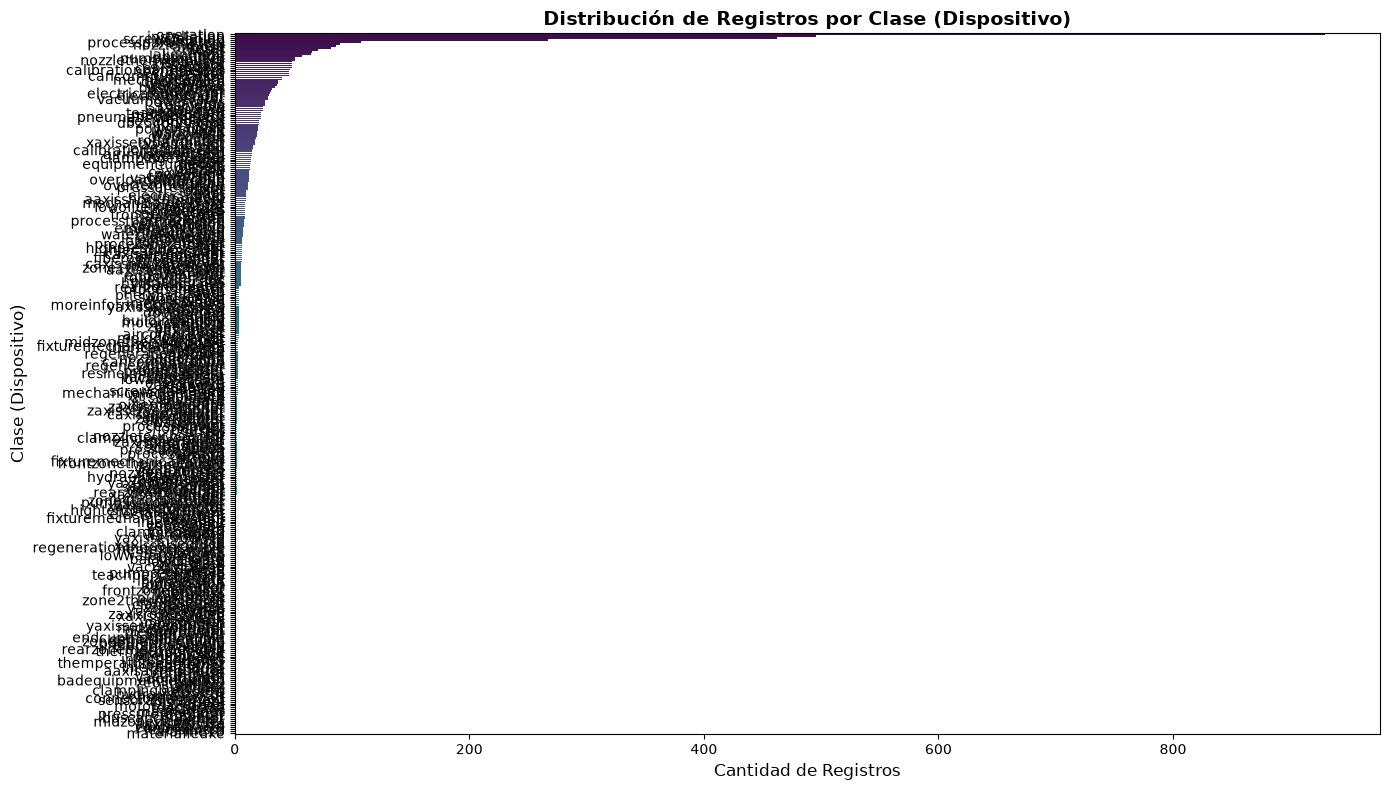

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Obtener el conteo de registros por clase
conteo_clases = y.value_counts()

# 2. Configurar la figura del gráfico
plt.figure(figsize=(14, 8))

# Crear un gráfico de barras horizontales para leer bien los nombres de las clases
sns.barplot(
    x=conteo_clases.values, y=conteo_clases.index, palette='viridis', hue=conteo_clases.index, legend=False
)

# 3. Añadir títulos y etiquetas
plt.title(
    'Distribución de Registros por Clase (Dispositivo)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Cantidad de Registros', fontsize=12)
plt.ylabel('Clase (Dispositivo)', fontsize=12)

# Ajustar diseño para que no se corte nada
plt.tight_layout()

# Mostrar el gráfico
plt.show()

### Vamos a agrupar los dispositivos que solo aparecen menos de 25 veces

In [5]:
from sklearn.model_selection import train_test_split

# 1. Aplicar el umbral de 25 para la cola larga (agrupar en "otros")
UMBRAL_MINIMO = 25
conteo_clases = y.value_counts()
clases_raras = conteo_clases[conteo_clases < UMBRAL_MINIMO].index

y_agrupada = y.apply(lambda x: 'otros' if x in clases_raras else x)
y = y_agrupada

print(f"Número de clases finales (incluyendo 'otros'): {y.nunique()}")


Número de clases finales (incluyendo 'otros'): 38


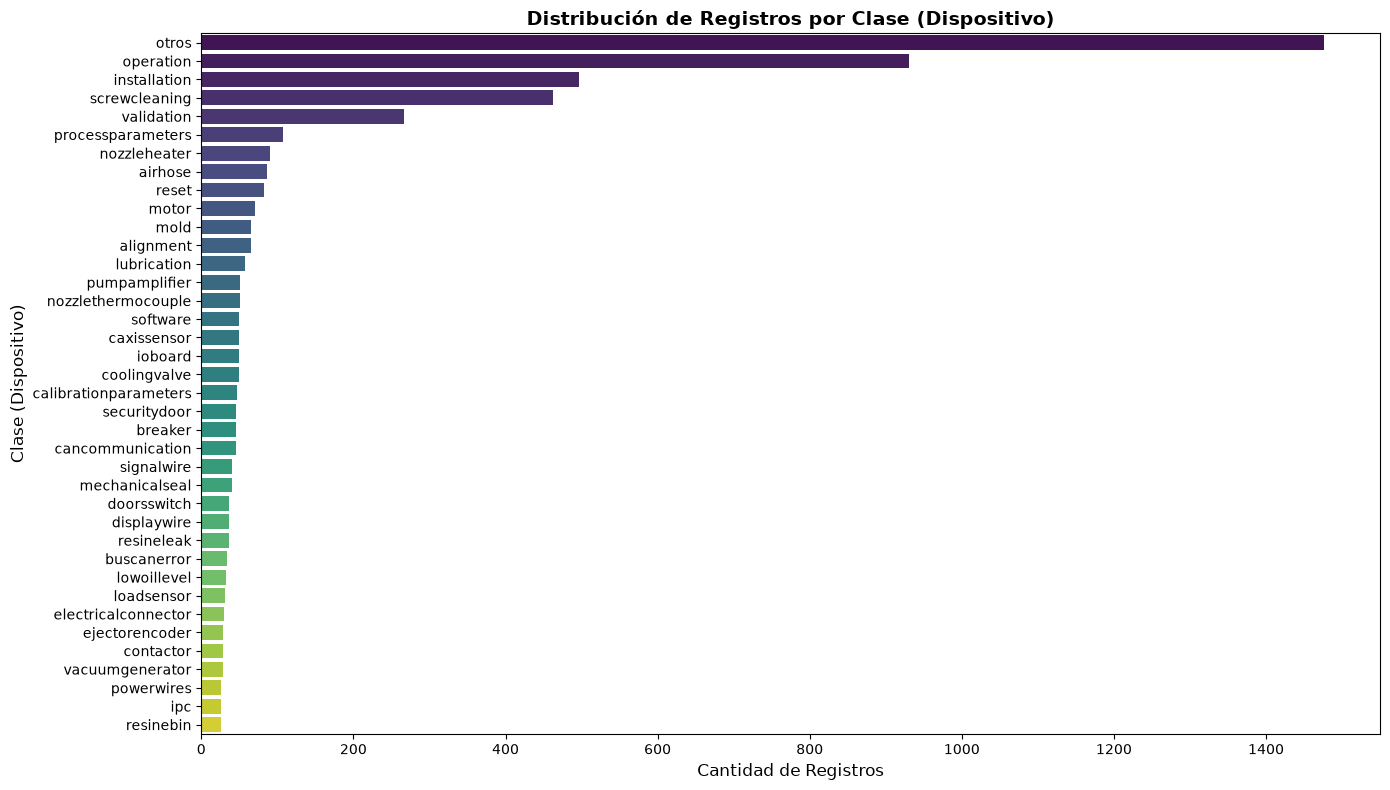

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Obtener el conteo de registros por clase
conteo_clases = y.value_counts()

# 2. Configurar la figura del gráfico
plt.figure(figsize=(14, 8))

# Crear un gráfico de barras horizontales para leer bien los nombres de las clases
sns.barplot(
    x=conteo_clases.values, y=conteo_clases.index, palette='viridis', hue=conteo_clases.index, legend=False
)

# 3. Añadir títulos y etiquetas
plt.title(
    'Distribución de Registros por Clase (Dispositivo)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Cantidad de Registros', fontsize=12)
plt.ylabel('Clase (Dispositivo)', fontsize=12)

# Ajustar diseño para que no se corte nada
plt.tight_layout()

# Mostrar el gráfico
plt.show()

### Dividimos el dataset entre entrenamiento, validacion y test con 60-20-20

In [7]:

# División 60 / 20 / 20 (Train / Validation / Test)
# Paso A: Separar el Test final (20%) y dejar el 80% restante (Train + Val)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Del 80% restante, dividir para obtener Validación (20% del total original, 
# que equivale al 25% del conjunto X_train_val) y Entrenamiento (60% del total)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val
)

# Verificar las dimensiones de nuestros conjuntos
print(f"\nDimensiones de los conjuntos:")
print(f"- Entrenamiento (Train - 60%): {X_train.shape[0]} registros")
print(f"- Validación (Val - 20%):     {X_val.shape[0]} registros")
print(f"- Prueba Final (Test - 20%):  {X_test.shape[0]} registros")


Dimensiones de los conjuntos:
- Entrenamiento (Train - 60%): 3131 registros
- Validación (Val - 20%):     1044 registros
- Prueba Final (Test - 20%):  1044 registros


### Creamos un modelo de Baseline usando vectorizacion TF-IDF
### En este usamos class_weight balanced lo cual le da el mismo valor a cada calse, penalizando mas a las pequenas y menos a las clases con muchos registros

In [8]:
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
import numpy as np

# Listas para acumular las etiquetas reales y las predichas de todo el proceso de CV
y_true_all = []
y_pred_all = []

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Generando predicciones Out-Of-Fold para el reporte detallado...\n")

for train_idx, val_idx in kf.split(X_train_val, y_train_val):
    X_f_train = X_train_val.iloc[train_idx] if hasattr(X_train_val, 'iloc') else X_train_val[train_idx]
    y_f_train = y_train_val.iloc[train_idx] if hasattr(y_train_val, 'iloc') else y_train_val[train_idx]
    
    X_f_val = X_train_val.iloc[val_idx] if hasattr(X_train_val, 'iloc') else X_train_val[val_idx]
    y_f_val = y_train_val.iloc[val_idx] if hasattr(y_train_val, 'iloc') else y_train_val[val_idx]

    # Vectorización independiente por fold (evita data leakage)
    tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))
    X_f_train_tfidf = tfidf.fit_transform(X_f_train)
    X_f_val_tfidf = tfidf.transform(X_f_val)

    # Entrenar modelo con pesos balanceados
    model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
    model.fit(X_f_train_tfidf, y_f_train)

    # Predecir en el fold de validación actual
    y_pred = model.predict(X_f_val_tfidf)
    
    # Acumular resultados
    y_true_all.extend(y_f_val)
    y_pred_all.extend(y_pred)

# Imprimir el reporte de clasificación global consolidado
print("="*65)
print("REPORTE DE CLASIFICACIÓN DETALLADO (5-Fold CV - Out-Of-Fold)")
print("="*65)
print(classification_report(y_true_all, y_pred_all, zero_division=0))

Generando predicciones Out-Of-Fold para el reporte detallado...

REPORTE DE CLASIFICACIÓN DETALLADO (5-Fold CV - Out-Of-Fold)
                       precision    recall  f1-score   support

              airhose       0.34      0.87      0.49        69
            alignment       0.59      0.92      0.72        52
              breaker       0.46      0.70      0.56        37
          buscanerror       0.05      0.11      0.07        27
calibrationparameters       0.31      0.68      0.43        38
     cancommunication       0.14      0.30      0.19        37
          caxissensor       0.21      0.77      0.33        39
            contactor       0.42      0.73      0.53        22
         coolingvalve       0.24      0.79      0.37        39
          displaywire       0.30      0.57      0.40        30
          doorsswitch       0.37      0.63      0.46        30
       ejectorencoder       0.34      0.83      0.48        23
  electricalconnector       0.09      0.17      0.12  

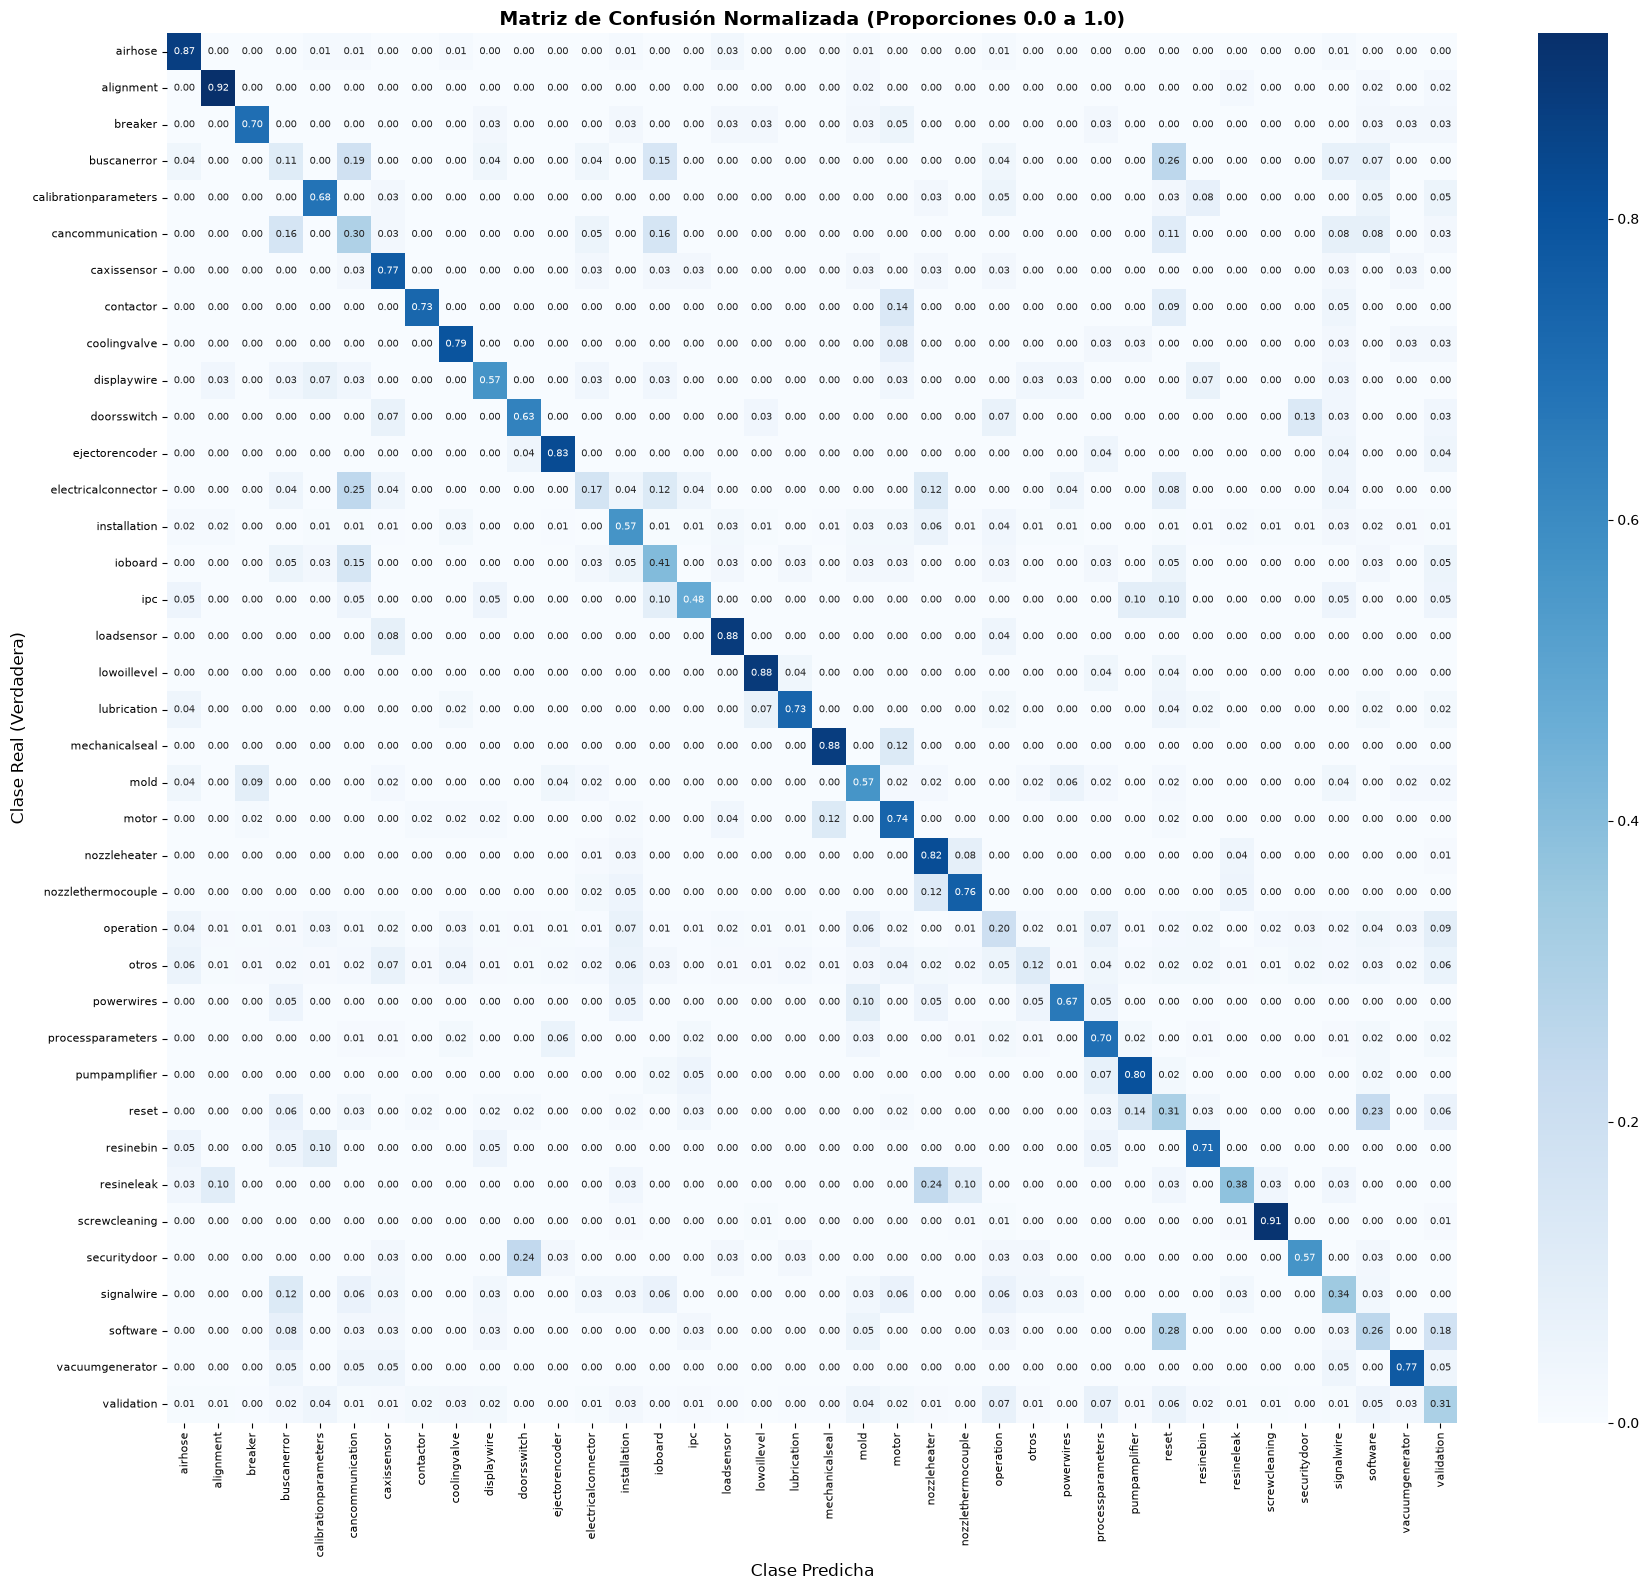

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# 1. Calcular la matriz de confusión estándar con todas las etiquetas únicas
etiquetas_clases = sorted(list(set(y_true_all)))
cm = confusion_matrix(y_true_all, y_pred_all, labels=etiquetas_clases)

# 2. Normalizar la matriz por filas (suma de cada fila = 1.0 o 100%)
# Esto convierte los conteos absolutos en proporciones/probabilidades
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
# Opcional: si quieres ver porcentajes directos de 0 a 100, multiplica por 100 y usa fmt='.1f'
# cm_norm = cm_norm * 100

# 3. Configurar la figura grande
plt.figure(figsize=(18, 16))

# 4. Crear el mapa de calor con los valores normalizados
sns.heatmap(
    cm_norm, 
    annot=True,            # Muestra los decimales (proporciones de 0.0 a 1.0)
    fmt='.2f',             # Dos decimales de precisión
    cmap='Blues',          # Escala de colores
    annot_kws={"size": 7}, # Tamaño de letra pequeño para las 38 clases
    xticklabels=etiquetas_clases,
    yticklabels=etiquetas_clases
)

# 5. Títulos y formato
plt.title('Matriz de Confusión Normalizada (Proporciones 0.0 a 1.0)', fontsize=14, fontweight='bold')
plt.xlabel('Clase Predicha', fontsize=12)
plt.ylabel('Clase Real (Verdadera)', fontsize=12)

plt.xticks(rotation=90, fontsize=8)
plt.yticks(fontsize=8)

plt.tight_layout()
plt.show()

### Probamos con un transformador pre entrenado

In [10]:
import numpy as np
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, classification_report

# 1. Cargar el modelo de embeddings multilingüe (optimizado para español)
print("Cargando modelo de embeddings multilingüe...")
embedder = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2') 

# 2. Generar embeddings para todo el dataset de entrenamiento/validación
print("Generando embeddings semánticos para los textos en español...")
X_train_val_embeddings = embedder.encode(
    X_train_val.tolist(), 
    show_progress_bar=True, 
    batch_size=64
)

# 3. Configurar Validación Cruzada de 5 pliegues con los embeddings
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

macro_f1_embeddings = []
weighted_f1_embeddings = []

print("\nIniciando Validación Cruzada con Embeddings Multilingües...\n")

for fold, (train_idx, val_idx) in enumerate(kf.split(X_train_val_embeddings, y_train_val)):
    # Separar datos usando los vectores densos
    X_f_train = X_train_val_embeddings[train_idx]
    y_f_train = y_train_val.iloc[train_idx] if hasattr(y_train_val, 'iloc') else y_train_val[train_idx]
    
    X_f_val = X_train_val_embeddings[val_idx]
    y_f_val = y_train_val.iloc[val_idx] if hasattr(y_train_val, 'iloc') else y_train_val[val_idx]

    # Entrenar el clasificador sobre los vectores semánticos con balanceo de clases
    model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
    model.fit(X_f_train, y_f_train)

    # Evaluar
    y_pred = model.predict(X_f_val)
    
    f1_macro = f1_score(y_f_val, y_pred, average='macro', zero_division=0)
    f1_weighted = f1_score(y_f_val, y_pred, average='weighted', zero_division=0)
    
    macro_f1_embeddings.append(f1_macro)
    weighted_f1_embeddings.append(f1_weighted)
    
    print(f"Fold {fold + 1} -> Macro F1: {f1_macro:.4f} | Weighted F1: {f1_weighted:.4f}")

print("\n----------------------------------------------------")
print(f"Promedio Macro F1 (Embeddings Multilingües):    {np.mean(macro_f1_embeddings):.4f}")
print(f"Promedio Weighted F1 (Embeddings Multilingües): {np.mean(weighted_f1_embeddings):.4f}")
print("----------------------------------------------------")

c:\Users\ngedg\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Cargando modelo de embeddings multilingüe...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2423.35it/s]


Generando embeddings semánticos para los textos en español...


Batches: 100%|██████████| 66/66 [00:02<00:00, 26.60it/s]



Iniciando Validación Cruzada con Embeddings Multilingües...

Fold 1 -> Macro F1: 0.3479 | Weighted F1: 0.3509
Fold 2 -> Macro F1: 0.3651 | Weighted F1: 0.3740
Fold 3 -> Macro F1: 0.3632 | Weighted F1: 0.3503
Fold 4 -> Macro F1: 0.3552 | Weighted F1: 0.3654
Fold 5 -> Macro F1: 0.3697 | Weighted F1: 0.3715

----------------------------------------------------
Promedio Macro F1 (Embeddings Multilingües):    0.3602
Promedio Weighted F1 (Embeddings Multilingües): 0.3624
----------------------------------------------------


En este caso el transformer performeo pero que el baseline de vectorize IDF, esto se debe a que el transformer considera mas el significado semantico de las palabras y el otro no.

### Creamos un transformer personalizado para el dataset

In [12]:
import numpy as np
import torch
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset

# 1. Preparar las etiquetas categóricas convirtiéndolas a números enteros (0 a 37)
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train_val)
# Si tienes tu split de prueba separado, codifícalo también; 
# por ahora usaremos X_train_val y podemos hacer un split interno para validación o usar un fold.

# 2. Cargar el tokenizador y el modelo BETO en español
model_name = "dccuchile/bert-base-spanish-wwm-uncased"
print(f"Cargando modelo base: {model_name}...")

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(
    model_name, 
    num_labels=len(label_encoder.classes_)
)

# 3. Función de tokenización
def tokenize_function(examples):
    return tokenizer(
        examples['text'], 
        padding="max_length", 
        truncation=True, 
        max_length=512  # Ajusta según la longitud promedio de tus descripciones
    )

# Separar un conjunto interno de validación (ej. 80% train, 20% val para el entrenamiento del Transformer)
X_tr, X_va, y_tr, y_va = train_test_split(
    X_train_val.tolist(), 
    y_train_encoded, 
    test_size=0.2, 
    random_state=42, 
    stratify=y_train_encoded
)

# Crear Datasets de Hugging Face
train_dataset = Dataset.from_dict({'text': X_tr, 'label': y_tr}).map(tokenize_function, batched=True)
val_dataset = Dataset.from_dict({'text': X_va, 'label': y_va}).map(tokenize_function, batched=True)

# 4. Configurar los hiperparámetros de entrenamiento
training_args = TrainingArguments(
    output_dir='./results_beto',
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,          # Tasa de aprendizaje estándar óptima para BERT/BETO
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=10,           # 3 a 4 épocas suelen ser suficientes para evitar sobreajuste
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="loss",
    logging_steps=50,
    save_total_limit=1
)

# 5. Inicializar el Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
)

print("\nIniciando Fine-Tuning de BETO...")
trainer.train()

# 6. Evaluar el modelo ajustado
eval_results = trainer.evaluate()
print("\nResultados de evaluación con BETO:")
print(eval_results)

Cargando modelo base: dccuchile/bert-base-spanish-wwm-uncased...


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 19444.58it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
bert.pooler.dense.bias                     | MISSING    | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from diffe


Iniciando Fine-Tuning de BETO...


Epoch,Training Loss,Validation Loss
1,2.221484,2.063103
2,1.835195,1.748053
3,1.512797,1.684622
4,1.139705,1.667806
5,0.934772,1.692955
6,0.731802,1.783129
7,0.549947,1.845315
8,0.503546,1.933575
9,0.414801,1.975922
10,0.308908,1.970406


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.81it/s]


Training Loss,Validation Loss,Epoch
0.308908,1.667806,10



Resultados de evaluación con BETO:
{'eval_loss': 1.667805790901184}


In [ ]:
import numpy as np
from sklearn.metrics import f1_score, classification_report

# 1. Obtener las predicciones del mejor modelo guardado en el conjunto de validación
predictions = trainer.predict(val_dataset)
y_pred = np.argmax(predictions.predictions, axis=1)

# 2. Calcular métricas finales
macro_f1_beto = f1_score(y_va, y_pred, average='macro', zero_division=0)
weighted_f1_beto = f1_score(y_va, y_pred, average='weighted', zero_division=0)

print(f"🚀 Macro F1 con BETO:    {macro_f1_beto:.4f}")
print(f"🚀 Weighted F1 con BETO: {weighted_f1_beto:.4f}")

# 3. Reporte detallado por clase (opcional para ver los "rebeldes")
print("\nReporte de clasificación detallado:")
print(classification_report(y_va, y_pred, target_names=label_encoder.classes_, zero_division=0))

🚀 Macro F1 con BETO:    0.3336
🚀 Weighted F1 con BETO: 0.5454

Reporte de clasificación detallado:
                       precision    recall  f1-score   support

              airhose       0.50      0.50      0.50        14
            alignment       0.78      0.70      0.74        10
              breaker       0.75      0.43      0.55         7
          buscanerror       0.00      0.00      0.00         5
calibrationparameters       0.80      0.50      0.62         8
     cancommunication       0.00      0.00      0.00         7
          caxissensor       0.43      0.38      0.40         8
            contactor       0.00      0.00      0.00         5
         coolingvalve       0.00      0.00      0.00         8
          displaywire       0.00      0.00      0.00         6
          doorsswitch       1.00      0.67      0.80         6
       ejectorencoder       0.00      0.00      0.00         5
  electricalconnector       0.00      0.00      0.00         5
         installat

### El problema principal son algunas clases las cuales tienen tan pocos registros y estos son ta distintos que el modelo no los esta tomando en cuenta.

## Usamos Weighted Cross-Entropy Loss para aumentar la penalizacion de los errores en las clases pequeñas haciendo que el modelo las tome mas en cuenta.

In [13]:
import torch
import torch.nn as nn
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, classification_report
from transformers import Trainer, TrainingArguments, AutoTokenizer, AutoModelForSequenceClassification
from datasets import Dataset

# 1. Calcular pesos inversos para balancear las 38 clases
# Penalizará proporcionalmente los errores en clases pequeñas
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_tr),
    y=y_tr
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Pesos calculados para {len(class_weights)} clases. Rango de pesos: min={class_weights.min():.2f}, max={class_weights.max():.2f}")

# 2. Crear un Trainer personalizado que incorpore los class_weights en la pérdida
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get("labels")
        # Forward pass del modelo
        outputs = model(**inputs)
        logits = outputs.get("logits")
        
        # Calcular CrossEntropyLoss utilizando los pesos de clase calculados
        loss_fct = nn.CrossEntropyLoss(weight=class_weights_tensor)
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        
        return (loss, outputs) if return_outputs else loss

# 3. Cargar una instancia limpia del modelo BETO
model_name = "dccuchile/bert-base-spanish-wwm-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(
    model_name, 
    num_labels=len(label_encoder.classes_)
)

# 4. Configurar argumentos de entrenamiento optimizados para clases desbalanceadas
training_args = TrainingArguments(
    output_dir='./results_beto_weighted',
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=8,             # Damos un poco más de margen para converger
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="loss",
    logging_steps=100,
    save_total_limit=1
)

# 5. Inicializar el Custom WeightedTrainer
trainer_weighted = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
)

print("\nIniciando entrenamiento de BETO con ponderación de clases (Class Weights)...")
trainer_weighted.train()

# 6. Evaluar y calcular las métricas finales
predictions = trainer_weighted.predict(val_dataset)
y_pred = np.argmax(predictions.predictions, axis=1)

macro_f1 = f1_score(y_va, y_pred, average='macro', zero_division=0)
weighted_f1 = f1_score(y_va, y_pred, average='weighted', zero_division=0)

print("\n" + "="*50)
print(f"🚀 Nuevo Macro F1 con BETO (Ponderado):    {macro_f1:.4f}")
print(f"🚀 Nuevo Weighted F1 con BETO (Ponderado): {weighted_f1:.4f}")
print("="*50 + "\n")

print(classification_report(y_va, y_pred, target_names=label_encoder.classes_, zero_division=0))

Pesos calculados para 38 clases. Rango de pesos: min=0.09, max=5.17


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 24574.05it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
bert.pooler.dense.bias                     | MISSING    | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from diffe


Iniciando entrenamiento de BETO con ponderación de clases (Class Weights)...


Epoch,Training Loss,Validation Loss
1,3.315952,3.077198
2,2.437958,2.228397
3,1.865583,1.869959
4,1.340974,1.661208
5,1.089271,1.566669
6,0.851476,1.578004
7,0.674008,1.546316
8,0.622435,1.568691


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.42it/s]



🚀 Nuevo Macro F1 con BETO (Ponderado):    0.4486
🚀 Nuevo Weighted F1 con BETO (Ponderado): 0.3866

                       precision    recall  f1-score   support

              airhose       0.35      0.86      0.50        14
            alignment       0.69      0.90      0.78        10
              breaker       0.38      0.86      0.52         7
          buscanerror       0.00      0.00      0.00         5
calibrationparameters       0.50      0.62      0.56         8
     cancommunication       0.14      0.14      0.14         7
          caxissensor       0.28      0.88      0.42         8
            contactor       0.67      0.80      0.73         5
         coolingvalve       0.60      0.75      0.67         8
          displaywire       0.14      0.17      0.15         6
          doorsswitch       0.31      0.67      0.42         6
       ejectorencoder       0.33      0.80      0.47         5
  electricalconnector       0.20      0.40      0.27         5
         installa

In [14]:
import torch
import torch.nn as nn
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, classification_report
from transformers import Trainer, TrainingArguments, AutoTokenizer, AutoModelForSequenceClassification

# 1. Calcular frecuencias y aplicar suavizado por raíz cuadrada (Square Root Class Weights)
unique_classes = np.unique(y_tr)
class_weights_raw = compute_class_weight(
    class_weight='balanced',
    classes=unique_classes,
    y=y_tr
)

# Aplicamos raíz cuadrada para suavizar la penalización extrema
smoothed_weights = np.sqrt(class_weights_raw)
class_weights_tensor = torch.tensor(smoothed_weights, dtype=torch.float32).to(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Pesos suavizados calculados. Rango: min={smoothed_weights.min():.2f}, max={smoothed_weights.max():.2f}")

# 2. Trainer personalizado con la función de pérdida ponderada y suavizada
class SmoothedWeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")
        
        # CrossEntropyLoss con los pesos suavizados
        loss_fct = nn.CrossEntropyLoss(weight=class_weights_tensor)
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        
        return (loss, outputs) if return_outputs else loss

# 3. Cargar una nueva instancia limpia del modelo BETO
model_name = "dccuchile/bert-base-spanish-wwm-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(
    model_name, 
    num_labels=len(label_encoder.classes_)
)

# 4. Configurar argumentos de entrenamiento
training_args = TrainingArguments(
    output_dir='./results_beto_smoothed',
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=6,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="loss",
    logging_steps=50,
    save_total_limit=1
)

# 5. Inicializar el SmoothedWeightedTrainer
trainer_smoothed = SmoothedWeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
)

print("\nIniciando entrenamiento de BETO con pesos de clase suavizados...")
trainer_smoothed.train()

# 6. Evaluar métricas finales
predictions = trainer_smoothed.predict(val_dataset)
y_pred = np.argmax(predictions.predictions, axis=1)

macro_f1 = f1_score(y_va, y_pred, average='macro', zero_division=0)
weighted_f1 = f1_score(y_va, y_pred, average='weighted', zero_division=0)

print("\n" + "="*50)
print(f"🚀 Macro F1 con BETO (Suavizado):    {macro_f1:.4f}")
print(f"🚀 Weighted F1 con BETO (Suavizado): {weighted_f1:.4f}")
print("="*50 + "\n")

print(classification_report(y_va, y_pred, target_names=label_encoder.classes_, zero_division=0))

Pesos suavizados calculados. Rango: min=0.30, max=2.27


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 14930.12it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
bert.pooler.dense.bias                     | MISSING    | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from diffe


Iniciando entrenamiento de BETO con pesos de clase suavizados...


Epoch,Training Loss,Validation Loss
1,2.893215,2.662741
2,2.188876,2.115117
3,1.790185,1.914169
4,1.351713,1.777572
5,1.212868,1.726295
6,1.082049,1.733154


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.81it/s]



🚀 Macro F1 con BETO (Suavizado):    0.4383
🚀 Weighted F1 con BETO (Suavizado): 0.5485

                       precision    recall  f1-score   support

              airhose       0.52      0.79      0.63        14
            alignment       0.82      0.90      0.86        10
              breaker       0.31      0.57      0.40         7
          buscanerror       0.00      0.00      0.00         5
calibrationparameters       0.62      0.62      0.62         8
     cancommunication       0.11      0.14      0.12         7
          caxissensor       0.40      0.75      0.52         8
            contactor       0.50      0.60      0.55         5
         coolingvalve       0.50      0.25      0.33         8
          displaywire       0.20      0.17      0.18         6
          doorsswitch       0.60      0.50      0.55         6
       ejectorencoder       0.33      0.20      0.25         5
  electricalconnector       0.00      0.00      0.00         5
         installation       0

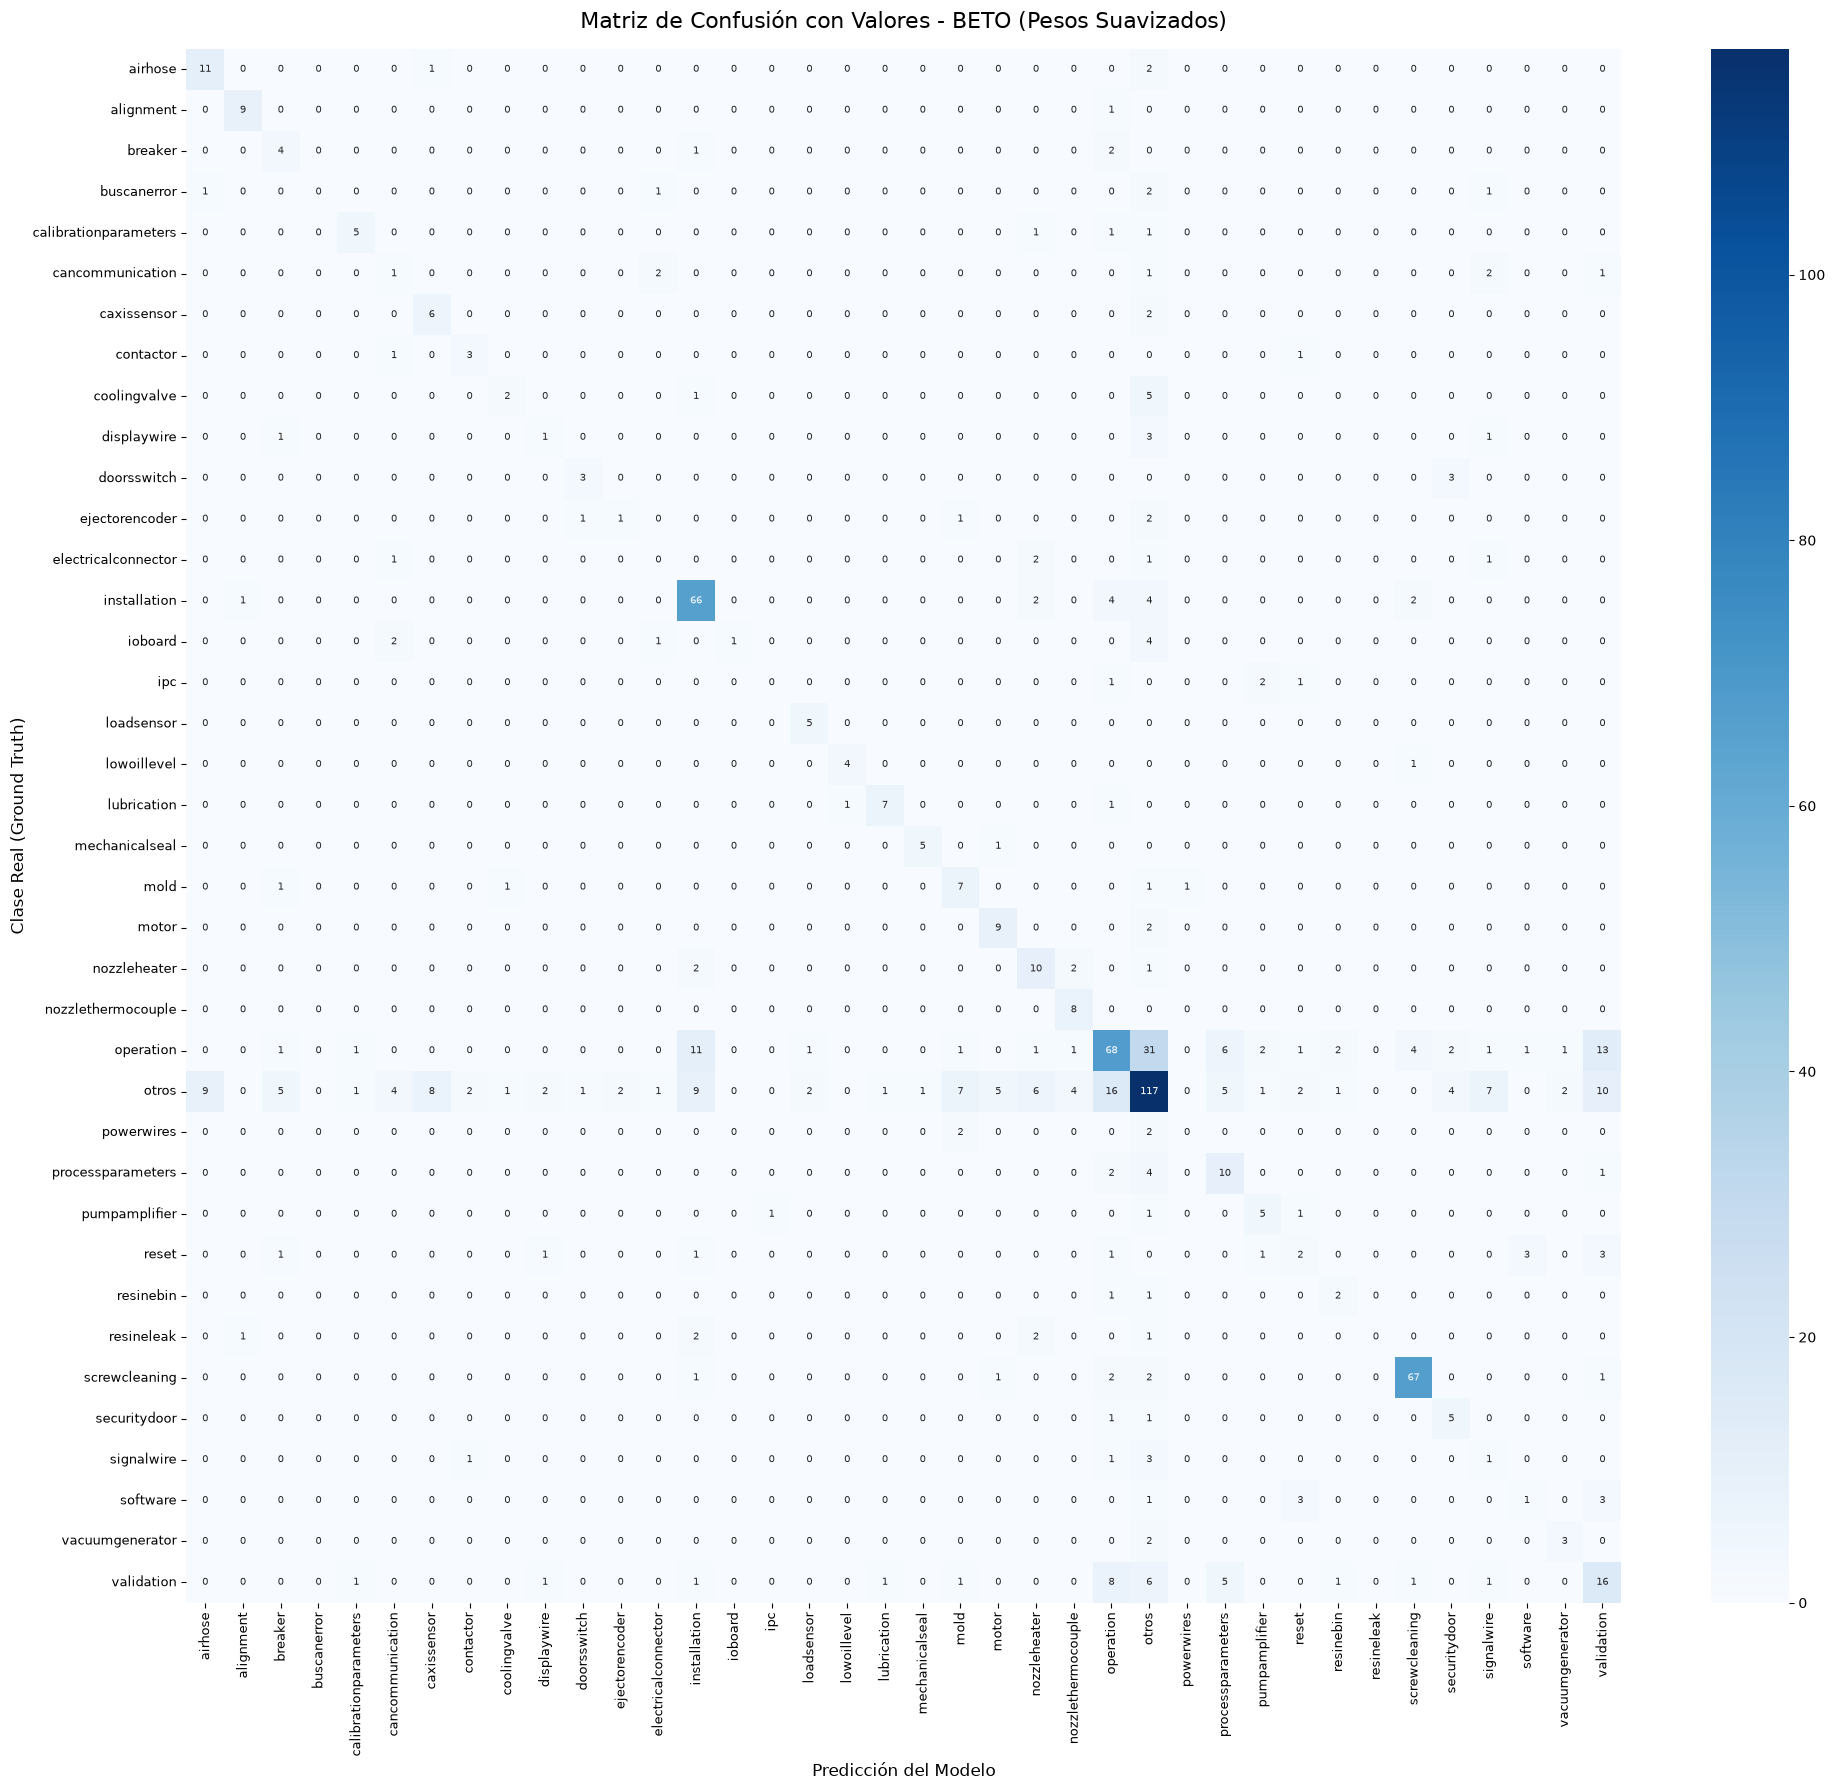

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Generar la matriz de confusión
cm = confusion_matrix(y_va, y_pred)

# 2. Configurar una figura amplia para acomodar las 38 clases
plt.figure(figsize=(20, 18))

# 3. Crear el mapa de calor con anotaciones numéricas
sns.heatmap(
    cm, 
    annot=True,             # Muestra los valores numéricos
    fmt='d',                # Formato de número entero
    cmap='Blues',           # Paleta de colores
    cbar=True,              # Barra lateral de intensidad
    xticklabels=label_encoder.classes_, 
    yticklabels=label_encoder.classes_,
    annot_kws={"size": 7}   # Tamaño de letra pequeño para que quepan los números
)

# 4. Estética de la gráfica
plt.title('Matriz de Confusión con Valores - BETO (Pesos Suavizados)', fontsize=16, pad=15)
plt.xlabel('Predicción del Modelo', fontsize=12)
plt.ylabel('Clase Real (Ground Truth)', fontsize=12)
plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.tight_layout()
plt.show()